In [1]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold

import torch
from torch import nn

from kagglekit import (
    Dataset,
    LinearClassifier,
    MLP,
    Trainer,
    plot_histories,
    summarize_histories,
)

## Load Datasets

In [2]:
df = pd.read_csv('../data/train.csv')
df_test = pd.read_csv('../data/test.csv')

df.shape, df_test.shape

((891, 12), (418, 11))

## Preprocessing

In [3]:
# Spelling variants fold into their common title; everything else that is rare
# (one-off honorifics like Jonkheer, or test-only ones like Dona) becomes 'Rare'.
TITLE_ALIASES = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}
COMMON_TITLES = ['Mr', 'Mrs', 'Miss', 'Master']


def add_features(df):
    df = df.copy()

    df['Deck'] = df['Cabin'].str.split().str[-1].str[0].fillna('unknown')
    df['CabinCount'] = df['Cabin'].str.split().str.len().fillna(0).astype(int)

    df['FamilySize'] = (df['SibSp'] + df['Parch'] + 1).fillna(0).astype(int)
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    title = df['Name'].str.extract(r',\s*([^.]*)\.')[0].str.strip().replace(TITLE_ALIASES)
    df['Title'] = title.where(title.isin(COMMON_TITLES), 'Rare')

    return df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived'], errors='ignore')

In [4]:
class Preprocessor:
    def fit(self, df):
        X = add_features(df)

        self.age_mean = X['Age'].mean()
        self.fare_median = X['Fare'].median()
        self.embarked_mode = X['Embarked'].mode()[0]
        X = self._impute(X)

        self.numeric_cols = X.select_dtypes(include='number').columns.tolist()
        self.categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

        self.means = X[self.numeric_cols].mean()
        self.stds = X[self.numeric_cols].std()

        self.columns = pd.get_dummies(X, columns=self.categorical_cols).columns
        
        return self

    def transform(self, df):
        X = self._impute(add_features(df))

        X[self.numeric_cols] = (X[self.numeric_cols] - self.means) / self.stds

        X = pd.get_dummies(X, columns=self.categorical_cols, dtype=int)
        
        return X.reindex(columns=self.columns, fill_value=0)

    def _impute(self, X):
        return X.fillna({'Age': self.age_mean, 'Fare': self.fare_median, 'Embarked': self.embarked_mode})

In [5]:
def to_tensor(data):
    return torch.tensor(data.to_numpy(), dtype=torch.float32)


def to_labels(df):
    return torch.tensor(df['Survived'].to_numpy(), dtype=torch.int64)

## Linear Classifier: Adam, lr=0.01, epochs=100

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = LinearClassifier(in_features=X_train.shape[1])
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.01)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

### CV Score

The epoch with the lowest mean val loss across folds, and each fold's score at that epoch.

In [7]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 27


,val_loss,val_accuracy
1,0.3812,0.8492
2,0.4082,0.8258
3,0.4440,0.7978
4,0.4351,0.8090
5,0.3932,0.8371
mean,0.4123,0.8238
std,0.0268,0.0207


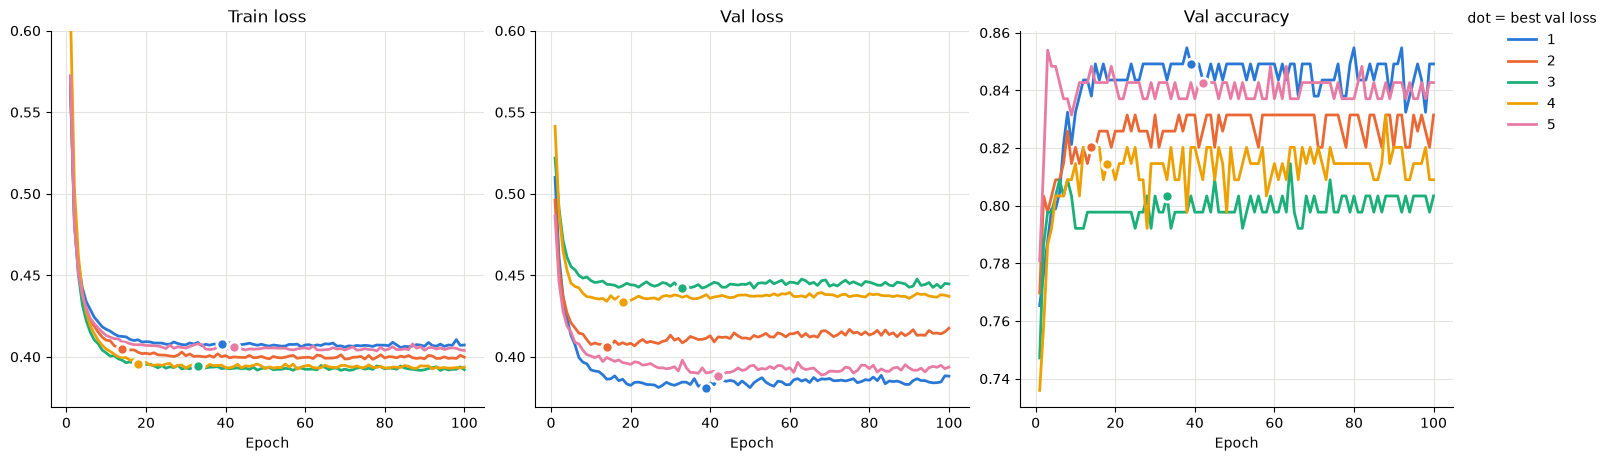

In [8]:
fig = plot_histories(fold_history)

## Linear Baseline 0.77272

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = LinearClassifier(in_features=X_train.shape[1])
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.01)
    
    trainer = Trainer(loss_fn, optim, max_epochs=9)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

In [13]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 9


,val_loss,val_accuracy
1,0.3957,0.8212
2,0.4105,0.8146
3,0.4489,0.8034
4,0.4369,0.8090
5,0.4013,0.8315
mean,0.4187,0.8159
std,0.0232,0.0109


## MLP: Adam, lr=0.001, epochs=100

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.001)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

### CV Score

In [10]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 81


,val_loss,val_accuracy
1,0.3752,0.8547
2,0.3918,0.8483
3,0.4284,0.8034
4,0.4249,0.8258
5,0.4045,0.8596
mean,0.4050,0.8384
std,0.0224,0.0234


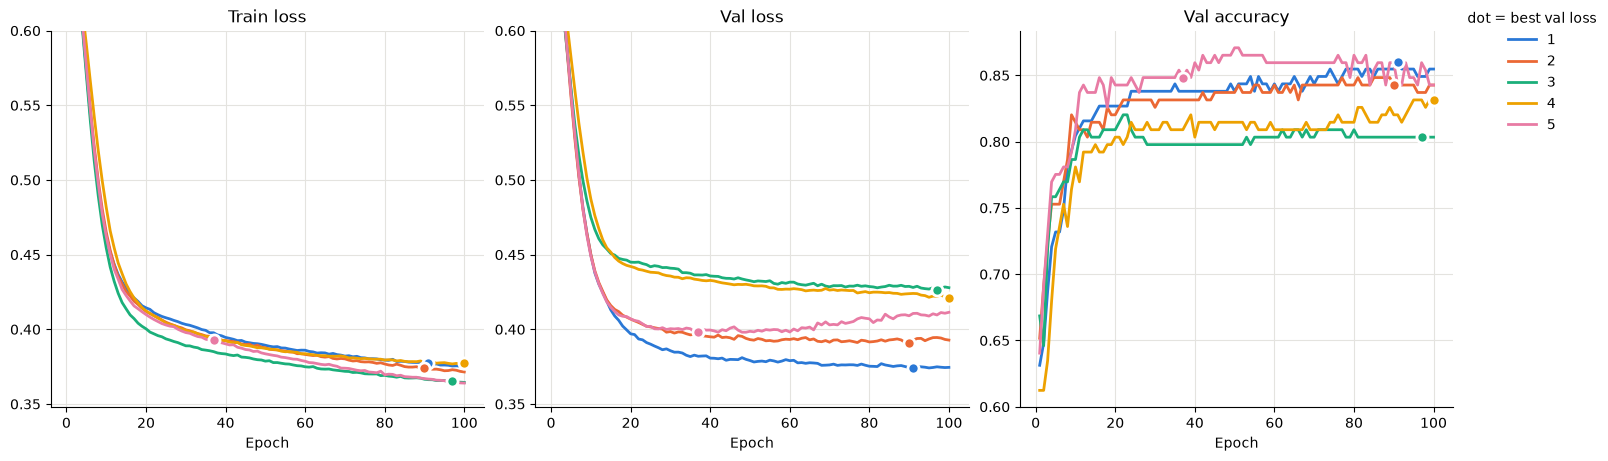

In [11]:
fig = plot_histories(fold_history)

## MLP Baseline 0.77272

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.001)
    
    trainer = Trainer(loss_fn, optim, max_epochs=15)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

In [15]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 15


,val_loss,val_accuracy
1,0.4131,0.8212
2,0.4160,0.8146
3,0.4508,0.8034
4,0.4517,0.7978
5,0.4148,0.8371
mean,0.4293,0.8148
std,0.0201,0.0155
